# Encapsulation

RECAP

### Classes and objects

A **class** is a template. It describes what something has (its data) and what it can do (its behavior).

An **object** is one specific thing created from that template. You can make as many objects from one class as you want, and each one keeps its own data.

For example, an e-wallet app has one design, but millions of accounts. The design is the class. Each person's account is an object.

In [ ]:
class Wallet:
    def __init__(self):         #dunder
        self.balance = 0

    def show(self):
        print("Balance:", self.balance)


my_wallet = Wallet()
my_wallet.show()

Balance: 0



**`class Wallet:`** defines the class. By convention, class names start with a capital letter.

**`__init__`** is a special method that Python runs automatically whenever a new object is created. You never call it yourself. Writing `Wallet()` is what triggers it. Its job is to set up the object's starting data.

That's two underscores before and two after (`__init__`). Python uses names with double underscores on both sides for built-in special methods,

**`self`** refers to the specific object that's running the code. `self.balance` means "this wallet's balance." If you have two wallets, `self` is whichever one you're working with at the time.

**`self.balance = 500`** creates an **attribute**, a variable that belongs to the object. Every new wallet starts with a balance of 500.

**`def show(self):`** defines a **method**, which is just a function that belongs to the class.

**`my_wallet.show()`** uses the dot to access something inside the object. Here it runs the `show` method on `my_wallet`.

Q

In [2]:
wallet_a = Wallet()
wallet_b = Wallet()

wallet_a.balance = 800

wallet_a.show()
wallet_b.show()

Balance: 800
Balance: 0


Changing `wallet_a` didn't affect `wallet_b`. Each object has its own copy of the data.

Additional Notes:

**`+=` and `-=`.** These are shortcuts. `x += 5` means `x = x + 5`, and `x -= 5` means `x = x - 5`.

**`if` / `elif` / `else`.** These run different code depending on a condition. We'll use them to check rules, like "is there enough money to send?"

In [3]:
grade = 85

if grade >= 90:
    print('A')
elif grade >= 80:
    print('B')
else:
    print('Failed')

B


## We've already been doing encapsulation

Encapsulation has two parts:

1. **Bundling:** keeping data and the code that works with that data together in one class.
2. **Hiding:** stopping outside code from changing the data directly.

Look at the `Wallet` class again. The balance (data) and the methods that use it (behavior) all live inside one class. That's bundling, so **every class you've written has already done the first part of encapsulation.**

What we haven't done yet is the second part. Right now, any code can reach into the wallet and change the balance to whatever it wants. Let's see why that's a problem.



In a real e-wallet app, you can't just type a new number into your balance. The only way to change it is by cashing in or sending money, and the app checks each request first.

Our wallet has no such protection:

In [5]:
class Wallet:
    def __init__(self):
        self.balance = 500

w = Wallet()

w.balance = 1000000

w.balance = -300
print (w.balance)


-300


<table><tr><td>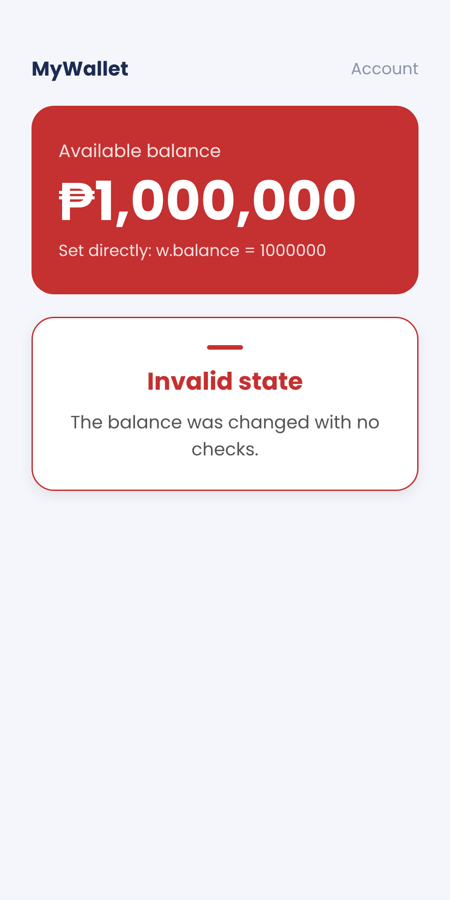</td><td>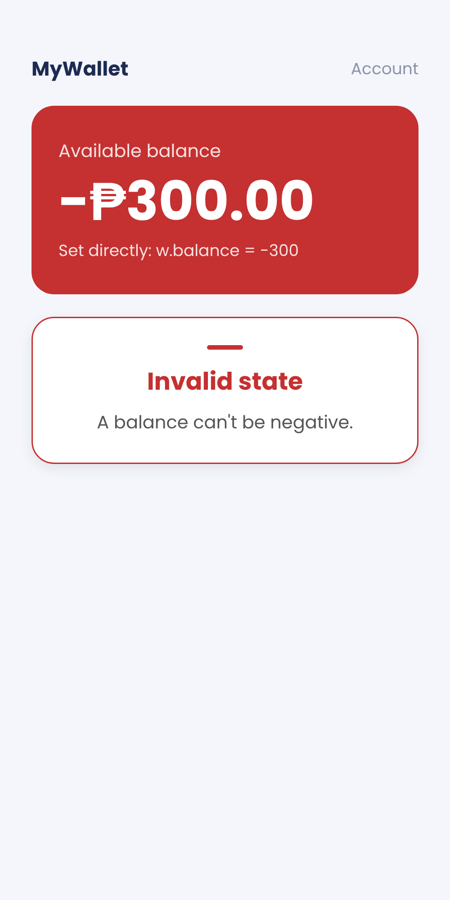</td></tr></table>

## We can fix this by adding methods

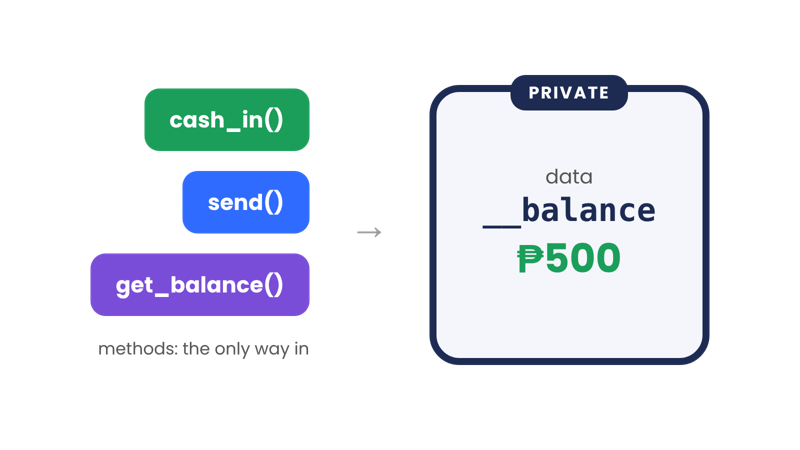

The idea is:

1. Make the balance **private**, so code outside the class can't touch it.
2. Provide **methods** that are the only way to view or change it. Each method checks the rules before changing anything.

### Step 1: Make the attribute private

In Python, you make an attribute private by putting two underscores **in front** of its name:

```python
self.balance     # public
self.__balance   # private
```

Be careful not to confuse this with `__init__`:

- `__init__` has underscores on **both sides**. It's a special built-in method.
- `__balance` has underscores **in front only**. It's a private attribute.

This next cell gives an error on purpose. Read the last line of the error message.

In [7]:
class Wallet:
    def __init__(self):
        self.__balance = 500

w = Wallet()
print(w.__balance)

AttributeError: 'Wallet' object has no attribute '__balance'

`AttributeError` means Python can't find `__balance` from outside the class. That's what we want, because the balance is now hidden.

But this creates a new problem. If outside code can't access the balance at all, how does anyone check it or add money?

### Step 2: Add methods that control access

Code **inside** the class can still use `self.__balance`. So we write methods that do the checking:

- `get_balance()` returns the balance so it can be viewed.
- `cash_in(amount)` adds money, but only if the amount is positive.
- `send(amount)` subtracts money, but only if there's enough.

In [ ]:
class Wallet:
    def __init__(self):
        self.__balance = 0

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount

In [17]:
cleos_wallet = Wallet()

print(cleos_wallet.get_balance()) # 0

cleos_wallet.cash_in(200)
print(cleos_wallet.get_balance()) # 200

cleos_wallet.send(1000) 
print(cleos_wallet.get_balance())

cleos_wallet.send(20)
print(cleos_wallet.get_balance())

cleos_wallet.__balance = 1000000
print(cleos_wallet.get_balance())


0
200
You have insufficient balance
200
180
180


# Recap: Encapsulation

Encapsulation has two parts, and our wallet now does both:

| Part | What it means | In our wallet |
|---|---|---|
| **Bundling** | Data and the code that uses it live together in one class. | The balance and `get_balance`, `cash_in`, `send` are all inside `Wallet`. |
| **Hiding** | Outside code can't change the data directly. | `__balance` is private. The only way to change it is through `cash_in` and `send`, which check the rules first. |

In [4]:
class Wallet:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount

# Inheritance

## The problem

GCash has more than one kind of wallet. For example:

- **GSave** is a savings account inside GCash. It has its own balance, separate from your main wallet, and it **earns interest**.
- **GInvest** lets you put money into investments. It also has its own balance, and there's a **minimum amount** you can put in at a time.

Both still need everything a normal wallet already has: a private balance, `get_balance`, `cash_in`, and `send`. Each one also has its own extras.

We *could* copy and paste the whole `Wallet` class twice and edit each copy. But then the same code would be in three places. If GCash changes a rule, like adding a fee every time you send money, we'd have to update all three classes, and it's easy to forget one.

**Inheritance** solves this. We write the shared code once, and new classes reuse it.

In [ ]:
### Gcash Wallet
class Wallet:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount

### GSave
class Gsave:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount
    # interest
###GInvest
class Ginvest:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount
    #max cap

### Parent and child classes

When a new class is built on top of an existing one:

- The existing class is the **parent**. Here, that's `Wallet`.
- The new class is the **child**. Here, `GSave` and `GInvest` are both children of `Wallet`. A parent can have as many children as you want.

The child automatically gets **everything** the parent has: all its attributes and all its methods. On top of that, it can:

1. **add** new things the parent doesn't have (like GSave's interest rate), and
2. **change** how some of the parent's methods work (like GInvest's minimum amount for `cash_in`).


Each GSave is still its own object with its own balance. Inheritance shares the **code**, not the money.

You might also see parents called **base classes** or **superclasses**, and children called **subclasses**. They mean the same thing.

### Step 1: Make a child class

To make a child class, put the parent's name in brackets after the new class name:

```python
class GSave(Wallet):
```

In [1]:
### Gcash Wallet - PARENT
class Wallet:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount

### GSave 
class Gsave(Wallet):
    pass

gsave_account = Gsave()
gcash_account = Wallet()

print("Gsave balance: ", gsave_account.get_balance())
gsave_account.cash_in(1000)
print("Gsave balance: ", gsave_account.get_balance())

print("Gcash balance: ", gcash_account.get_balance())

Gsave balance:  0
Gsave balance:  1000
Gcash balance:  0


We never wrote `cash_in`, `send`, or `get_balance` inside `GSave`, but they work. The child got all of them from `Wallet`.

### Step 2: Give the child something new

A GSave that's identical to a normal wallet isn't very useful. Let's give it what makes it a savings account: an `add_interest` method that adds 2% to the balance.

A first attempt might look like this. This cell gives an error on purpose. Read the last line of the error message.

In [2]:
class GSave(Wallet):
    def add_interest(self):
        interest = self.__balance * 0.02
        self.__balance += interest


save = GSave()
save.cash_in(1000)
save.add_interest()

AttributeError: 'GSave' object has no attribute '_GSave__balance'

In [3]:
class GSave(Wallet):
    def add_interest(self):
        interest = self.get_balance() * 0.02
        self.cash_in(interest)


save = GSave()
save.cash_in(1000)
save.add_interest()
print(save.get_balance())

1020.0


The `.0` at the end is there because multiplying by a decimal (`0.02`) always gives a decimal.

### Step 3: Give the child its own data with `super()`

Right now the interest rate is stuck at 2%. What if each GSave account should have its own rate?

Then `GSave` needs its own `__init__` that takes the rate as an input. `__init__` can take inputs just like any other method: writing `GSave(0.05)` passes `0.05` into `rate`.

But there's a catch. `Wallet`'s `__init__` is the one that creates the balance, and we don't want to rewrite it.

`super()` means "the parent class" (it comes from the word *superclass*). So `super().__init__()` says: *run the parent's setup first, then I'll add my own part.*

In [4]:
class GSave(Wallet):
    def __init__(self, rate):
        super().__init__()     # let Wallet set up the balance first
        self.rate = rate       # then add GSave's own attribute

    def add_interest(self):
        interest = self.get_balance() * self.rate
        self.cash_in(interest)


save = GSave(0.05)
save.cash_in(1000)
save.add_interest()
print(save.get_balance())

1050.0


Q

What happens if we forget the `super().__init__()` line?

In [ ]:
class BrokenSave(Wallet):
    def __init__(self, rate):
        self.rate = rate


b = BrokenSave(0.05)
b.cash_in(1000)

When a child writes its own `__init__`, Python runs **that one instead of** the parent's. So without `super().__init__()`, the parent's setup never ran and the balance was never created. `cash_in` then tries to add to a balance that doesn't exist.

Rule of thumb: if a child has its own `__init__`, its first line should almost always be `super().__init__()`.

### Step 4: Change how an inherited method works

Now GInvest. It works like a normal wallet, except there's a **minimum amount** you can put in at a time. In our version, the minimum is 50.

So GInvest needs its own `cash_in`. If a child defines a method with the **same name** as one in the parent, the child's version is used instead. This is called **overriding**.

We still don't want to rewrite the adding part, though. So GInvest checks its own rule first, then passes the actual cash in to the parent with `super().cash_in(amount)`.

In [5]:
class GInvest(Wallet):
    def __init__(self, minimum):
        super().__init__()
        self.minimum = minimum

    def cash_in(self, amount):
        if amount < self.minimum:
            print("Minimum investment is", self.minimum)
        else:
            super().cash_in(amount)   # the parent does the normal check and adds it


invest = GInvest(50)
invest.cash_in(30)
invest.cash_in(500)
invest.send(200)
print(invest.get_balance())

Minimum investment is 50
300


Here's what happened:

1. `cash_in(30)`: GInvest's own rule stops it. Below the minimum of 50.
2. `cash_in(500)`: passes the minimum, so `super().cash_in(500)` runs. The parent adds it.
3. `send(200)`: GInvest didn't write its own `send`, so this is just `Wallet`'s `send`.

Only the methods you override change. Everything else still comes from the parent.

## Exercise: Business wallet

Businesses pay a fee every time they send money. Create a `BusinessWallet` that:

1. Inherits from `Wallet`.
2. Has a `fee` attribute, given when the wallet is created: `BusinessWallet(15)`.
3. Overrides `send` so that it sends `amount + fee` in total.

It's the same idea as GInvest, but this time you're overriding `send` instead of `cash_in`. Use `super()` instead of copying code from `Wallet`. Replace the `...` with your code.

In [ ]:
class BusinessWallet(Wallet):
    def __init__(self, fee):
        ...

    def send(self, amount):
        ...


biz = BusinessWallet(15)
biz.cash_in(1000)
biz.send(100)
print(biz.get_balance())   # expected: 885
biz.send(880)              # expected: You have insufficient balance  (880 + 15 is more than 885)
print(biz.get_balance())   # expected: 885

# Polymorphism

## Recap: where we left off

Last session, `Wallet` was the **parent**, and `GSave` and `GInvest` were its **children**:

- A child gets everything the parent has: the private balance, `get_balance`, `cash_in`, `send`.
- `super()` means "the parent's version". `super().__init__()` lets the parent set up the balance before the child adds its own attribute.
- **Overriding** is when a child writes its own version of a parent's method. `GInvest` overrides `cash_in` to add a minimum.

In [ ]:
### Gcash Wallet - PARENT
class Wallet:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount


### GSave - CHILD (earns interest)
class GSave(Wallet):
    def __init__(self, rate):
        super().__init__() # let wallet set up the balance
        self.rate = rate    # GSave's own attribute

    def add_interest(self):
        interest = self.get_balance() * self.rate
        self.cash_in(interest)


### GInvest - CHILD (minimum amount per cash in)
class GInvest(Wallet):
    def __init__(self, minimum):
        super().__init__()
        self.minimum = minimum

    def cash_in(self, amount): # overrides Wallet's cash_in
        if amount < self.minimum:
            print("Minimum investment is", self.minimum)
        else:
            super().cash_in(amount)

ginvest = GInvest(50)
ginvest.send(100)

## What polymorphism is

*Poly* means many, *morph* means form. **Polymorphism** means the same method call can behave differently depending on which object it's called on.

You've already been doing it. `GInvest` has its own `cash_in`, while `Wallet` and `GSave` use the original one. Same call, `cash_in(30)`, different behavior.

### Step 1: Same call, different objects

Let's put a normal GCash wallet, a GSave, and a GInvest in one list, and cash in 30 to each of them with one loop.

Before you run it: which one of the three will refuse?

In [9]:
### Gcash Wallet - PARENT
class Wallet:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount


### GSave - CHILD (earns interest)
class GSave(Wallet):
    def __init__(self, rate):
        super().__init__() # let wallet set up the balance
        self.rate = rate    # GSave's own attribute

    def add_interest(self):
        interest = self.get_balance() * self.rate
        self.cash_in(interest)


### GInvest - CHILD (minimum amount per cash in)
class GInvest(Wallet):
    def __init__(self, minimum):
        super().__init__()
        self.minimum = minimum

    def cash_in(self, amount): # overrides Wallet's cash_in
        if amount < self.minimum:
            print("Minimum investment is", self.minimum)
        else:
            super().cash_in(amount)

In [13]:
gcash = Wallet() # 30
gsave = GSave(0.05)
ginvest = GInvest(50) # minimum 50 cash in

wallets = [gcash, gsave, ginvest]

for wallet in wallets:
    wallet.cash_in(30)
    print("Balance:", wallet.get_balance())

# gcash.cash_in(30)
# print("Balance:", gcash.get_balance())  # 30

# gsave.cash_in(30)
# print("Balance:", gsave.get_balance())  # 30

# ginvest.cash_in(30)
# print("Balance:", ginvest.get_balance())  # 0

Balance: 30
Balance: 30
Minimum investment is 50
Balance: 0


### Step 2: Same method name in every class

GCash runs an update at the end of every month:

- a normal GCash wallet doesn't change
- GSave earns interest
- GInvest grows (real investments can also go *down*, let's make it grow for now)

We'll give every class a method with the same name, `month_end`, and each one will do its own thing.

For this, `Wallet` itself needs a `month_end`, so all three classes are written again below. The children have to be rewritten too, because they were built from the *old* `Wallet`, which has no `month_end`.

1. every class now has a `month_end`
2. GSave's `add_interest` is gone (`month_end` does that job now)
3. GInvest now takes a second input, `growth`

In [14]:
### Gcash Wallet - PARENT
class Wallet:
    def __init__(self):
        self.__balance = 0

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount

    def month_end(self):
        print("Gcash wallet: no changes")


### GSave - CHILD (earns interest at month end)
class GSave(Wallet):
    def __init__(self, rate):
        super().__init__()
        self.rate = rate

    def month_end(self): # replaces older method, only earn interest every month end
        interest = self.get_balance() * self.rate
        self.cash_in(interest)
        print("GSave: earned ", interest, "interest")


### GInvest - CHILD (minimum amount per cash in, grow at month end)
class GInvest(Wallet):
    def __init__(self, minimum, growth):
        super().__init__()
        self.minimum = minimum
        self.growth = growth

    def cash_in(self, amount):
        if amount < self.minimum:
            print("Minimum investment is", self.minimum)
        else:
            super().cash_in(amount)

    def month_end(self):
        gain = self.get_balance() * self.growth
        super().cash_in(gain)
        print("GInvest: grew by", gain)

One line to look at closely. GInvest's `month_end` uses `super().cash_in(gain)`, **not** `self.cash_in(gain)`.

`self.cash_in` always means "**this object's own** version of `cash_in`". For a GInvest, that's the one with the minimum rule. So with `self.cash_in(gain)`, any month where it earned less than 50 would print "Minimum investment is 50" and the earnings would be refused.

`super().cash_in(gain)` skips GInvest's rule and goes straight to `Wallet`'s `cash_in`, which only checks that the amount is above 0.

Now one loop handles all of them. Predict the three final balances before running.

In [ ]:
gcash = Wallet()
gsave = GSave(0.05)
ginvest = GInvest(50, 0.10)

wallets = [gcash, gsave, ginvest, gcrypto]

for wallet in wallets:
    wallet.cash_in(1000)

for wallet in wallets:
    wallet.month_end()

print() # additional line
for wallet in wallets:
    print("Balance:", wallet.get_balance())

# Balance: 1000
# Balance: 1050
# Balance: 1100

Gcash wallet: no changes
GSave: earned  50.0 interest
GInvest: grew by 100.0

Balance: 1000
Balance: 1050.0
Balance: 1100.0


The loop never checks the type. It says "do your month-end update," and each object knows its own version.

This is why polymorphism matters. If GCash adds a new kind of wallet next year (say, GCrypto), **these loops don't change at all.** The new class only needs its own `month_end`.

## Exercise: Add a business wallet to the loop

GCash business accounts pay a **monthly maintenance fee of 50**, like a membership fee for having a business account. GCash takes it out automatically at the end of every month.

So the business wallet's `month_end` is about **taking money out**, while GSave and GInvest **add** money at month end.

Write `BusinessWallet` again on top of the new `Wallet`:

1. **Same as last session:** it's created with a `fee` (`BusinessWallet(15)`), and every `send` costs `amount + fee`.
2. **New:** `month_end` takes **exactly 50** out of the balance and prints `"Business wallet: paid 50 maintenance fee"`.

⚠️ The maintenance fee is **not** a send, so the 15 send fee should **not** be added to it. Start: 1000 → after maintenance: **950** (not 935).

Don't change the loops. Just fill in the class.

**Hint:** GInvest's `month_end` used `super().cash_in` to skip its own minimum rule. What does BusinessWallet need to skip?

In [ ]:
### BusinessWallet - CHILD (fee per send, maintenance 50 at month end)
class BusinessWallet(Wallet):
    def __init__(self, fee):
      super().__init__()
      self.fee = fee
      self.maintanance_fee = 50


    # # 1st
    # def send(self, amount):
    #   amount = self.amount + self.fee
    #   super().send(amount)

    # #2nd
    # def send(self, amount):
    #   self.amount = amount
    #   total_amount = self.amount + self.fee
    #   super().send(total_amount)

    # mine
    def send(self, amount):
          amount = amount + self.fee
          super().send(amount)

    def month_end(self):
      super().send(self.maintanance_fee)
      print("BusinessWallet: deducted by", self.maintanance_fee)



                                                                    #fee
wallets = [Wallet(), GSave(0.05), GInvest(50, 0.03), BusinessWallet(15)]

for wallet in wallets:
    wallet.cash_in(1000) # it will use the current wallet's cash_in method to cash in 1000

for wallet in wallets:
    wallet.month_end()   # it will use the current wallet's month_end method

print()
for wallet in wallets:
    print("Balance:", wallet.get_balance())  # it will use the current wallet's get_balance method to see its balance

# expected last line: Balance: 950   (not 935)

wallets[3].send(100) # 100 + 15
print("After send balance:", wallets[3].get_balance()) # 835

Gcash wallet: no changes
GSave: earned  50.0 interest
GInvest: grew by 30.0
BusinessWallet: deducted by 50

Balance: 1000
Balance: 1050.0
Balance: 1030.0
Balance: 950
After send balance: 835


*(double-click here to type)*

## Polymorphism in one sentence

Give different classes a method with the **same name**, and one loop can call it on all of them. Each object runs its own version, and the loop never needs an `if`.

# Abstraction

## Setup: run this first

This section is for a new session, so here's the newest `Wallet` (the one with `month_end`) again. Nothing prints when you run it. It's only the template.

In [ ]:
### Gcash Wallet - PARENT (same as last session)
class Wallet:
    def __init__(self):
        self.__balance = 0 # private

    def get_balance(self):
        return self.__balance

    def cash_in(self, amount):
        if amount > 0:
            self.__balance += amount
        else:
            print("Invalid amount, add something more than 0")

    def send(self, amount):
        if amount > self.__balance:
            print("You have insufficient balance")
        else:
            self.__balance -= amount

    def month_end(self):
        print("Gcash wallet: no changes")

## What abstraction is

When you tap **Send** in GCash, you don't see the balance check, the fraud check, or the database update. You only see the button. **Abstraction** means showing only what someone needs to *use* a thing, and hiding how it works.

It's a close cousin of encapsulation:

- **Encapsulation** is about *protecting* data (making `__balance` private).
- **Abstraction** is about *simplifying* how something is used (a few clear methods, with the details hidden).

In Python, abstraction is often done with an **abstract class**: a template that lists which methods every child *must* have, without filling them in itself. You can't create an object from the template, only from children that follow the rule.

Last session's last Q showed why that matters: polymorphism only works if every object really has the method. An abstract class is how you force that.

## The problem: GCash Pay Bills

GCash can pay bills: Meralco (electricity), Maynilad (water), PLDT (internet), and hundreds more. Every bill is **paid** the same way (the amount comes out of your GCash wallet), but the **amount** is computed differently:

- electricity depends on how many kWh you used
- water depends on how many cubic meters you used
- internet is a flat monthly plan

We want one general `Bill` that handles paying, plus a rule that says "every kind of bill must know how to compute its amount," without `Bill` saying how.

Also, nobody should be able to create a plain `Bill`. A bill that isn't electricity, water, or anything in particular doesn't have an amount.

### Step 1: Write an abstract class

Three new things here:

- `from abc import ABC, abstractmethod` loads Python's built-in tools for abstract classes. `abc` stands for *abstract base classes*. (Base class is another word for parent.)
- `class Bill(ABC):` makes `Bill` an abstract class. It's inheritance again: `Bill` is a child of `ABC`.
- `@abstractmethod` goes on the line above a method to mark it as a rule: **every child must write its own version of this.** The `pass` is there because `Bill` itself doesn't know how to compute anything.

In [ ]:
from abc import ABC, abstractmethod


### Bill - ABSTRACT PARENT (a template, not a real bill)
class Bill(ABC):
    def __init__(self, name):
        self.name = name

    @abstractmethod
    def compute_amount(self):
        pass                    # Bill doesn't know how. Every child must write this.

    def pay(self, wallet):
        amount = self.compute_amount()
        print("Paying", amount, "for", self.name)
        wallet.send(amount)

Notice that `pay` is a normal method. It calls `self.compute_amount()` without knowing how the amount is computed. That's the abstraction: `pay` only needs to know *that* every bill can compute its amount, not *how*.

Also notice that `pay` takes a **wallet object** as its input. Objects can be passed into methods like any other value.

This next cell gives an error on purpose. Read the last line.

In [ ]:
b = Bill("Mystery bill")

`TypeError`: Python won't let us create a plain `Bill`, because `compute_amount` hasn't been written yet. `Bill` is only a template.

### Step 2: Write the children

Each child fills in `compute_amount` its own way:

- Meralco charges 12 pesos per kWh (in our version)
- Maynilad charges 35 pesos per cubic meter (in our version)

Each child also calls `super().__init__(...)` to give the bill its name. This time there's something in the brackets, because `Bill`'s `__init__` needs a `name`.

In [ ]:
### ElectricBill - CHILD (Meralco: 12 pesos per kWh)
class ElectricBill(Bill):
    def __init__(self, kwh):
        super().__init__("Meralco")
        self.kwh = kwh

    def compute_amount(self):
        return self.kwh * 12


### WaterBill - CHILD (Maynilad: 35 pesos per cubic meter)
class WaterBill(Bill):
    def __init__(self, cubic_meters):
        super().__init__("Maynilad")
        self.cubic_meters = cubic_meters

    def compute_amount(self):
        return self.cubic_meters * 35

Now pay them from a wallet. Predict the final balance first: 150 kWh of electricity and 20 cubic meters of water, starting from 3000.

In [ ]:
cleos_wallet = Wallet()
cleos_wallet.cash_in(3000)

bills = [ElectricBill(150), WaterBill(20)]

for bill in bills:
    bill.pay(cleos_wallet)

print("Balance:", cleos_wallet.get_balance())

Look at `pay` again. It never mentions kWh or cubic meters. It only knows that every bill has a `compute_amount`, and the abstract class guarantees that every bill does. The details are hidden inside each child.

The loop is polymorphism again. Abstraction and polymorphism usually show up together: the abstract class sets the rule, and polymorphism lets one loop use it.

Q

What happens if a child forgets to write `compute_amount`? Guess first, then run. Pay attention to *when* the error happens.

In [ ]:
### GasBill - CHILD that forgot compute_amount
class GasBill(Bill):
    def __init__(self, kg):
        super().__init__("Gas")
        self.kg = kg


g = GasBill(11)

*(double-click here to type)*

Python refuses to create a `GasBill` because it broke the rule. The mistake shows up right away, when the object is created, not later when someone tries to pay with it. Catching mistakes early is one of the main reasons abstract classes exist.

## Exercise: Internet bill

*If we run out of time, finish this one at home. The expected output in the cell tells you if you got it right.*

Create an `InternetBill` that:

1. Inherits from `Bill`.
2. Is created with a `plan_price`: `InternetBill(1299)`.
3. Has the name `"PLDT"`.
4. Has a `compute_amount` that returns the plan price.

`cleos_wallet` from above has 500 left. Replace the `...` with your code.

In [ ]:
### InternetBill - CHILD (PLDT: flat monthly plan price)
class InternetBill(Bill):
    ...


net = InternetBill(1299)
net.pay(cleos_wallet)
# expected:
# Paying 1299 for PLDT
# You have insufficient balance

cleos_wallet.cash_in(1000)
net.pay(cleos_wallet)
print("Balance:", cleos_wallet.get_balance())   # expected: Balance: 201

*(double-click here to type)*

## Bonus Q

Think back to the polymorphism session, where `PlainWallet` had no `month_end` and the loop crashed. If `Wallet` had been an abstract class with `@abstractmethod` on `month_end`, when would the mistake have shown up instead?

*(double-click here to type)*

# Summary

| Idea | What it means | What it looked like in our GCash code |
|---|---|---|
| **Encapsulation** | Protect the data; change it only through methods. | `self.__balance`, changed only by `cash_in` and `send` |
| **Inheritance** | A new class starts with everything another class has. | `class GSave(Wallet):`, `class GInvest(Wallet):` |
| `super()` | Use the parent's version of a method. | `super().__init__()`, `super().cash_in(amount)`, `super().send(50)` |
| Overriding | A child writes its own version of a parent's method. | `GInvest`'s `cash_in` with a minimum, `BusinessWallet`'s `send` with a fee |
| **Polymorphism** | Same method call, different behavior per object. | one loop calling `cash_in()`, `month_end()` or `pay()` on a mix of objects |
| **Abstraction** | Show only what's needed to use something; hide the how. | `Bill` with `@abstractmethod compute_amount`, and `pay` that doesn't care how the amount is computed |